In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('/content/cleaned_support_tickets.csv')

In [3]:
df

,flags,utterance,category,intent,text_length,Lower_text,no_html,no_url,no_email,clean_text,tokens,filtered_tokens,lemmatized_tokens,lemmatized_text,processed_text
0,BM,I have problems with canceling an order,ORDER,cancel_order,7,i have problems with canceling an order,i have problems with canceling an order,i have problems with canceling an order,i have problems with canceling an order,i have problems with canceling an order,"['i', 'have', 'problems', 'with', 'canceling',...","['problems', 'canceling', 'order']","['problem', 'cancel', 'order']",problem cancel order,problem cancel order
1,BIM,how can I find information about canceling ord...,ORDER,cancel_order,8,how can i find information about canceling ord...,how can i find information about canceling ord...,how can i find information about canceling ord...,how can i find information about canceling ord...,how can i find information about canceling orders,"['how', 'can', 'i', 'find', 'information', 'ab...","['find', 'information', 'canceling', 'orders']","['find', 'information', 'cancel', 'order']",find information cancel order,find information cancel order
2,B,I need help with canceling the last order,ORDER,cancel_order,8,i need help with canceling the last order,i need help with canceling the last order,i need help with canceling the last order,i need help with canceling the last order,i need help with canceling the last order,"['i', 'need', 'help', 'with', 'canceling', 'th...","['need', 'help', 'canceling', 'last', 'order']","['need', 'help', 'cancel', 'last', 'order']",need help cancel last order,need help cancel last order
3,BIP,could you help me cancelling the last order I ...,ORDER,cancel_order,10,could you help me cancelling the last order i ...,could you help me cancelling the last order i ...,could you help me cancelling the last order i ...,could you help me cancelling the last order i ...,could you help me cancelling the last order i ...,"['could', 'you', 'help', 'me', 'cancelling', '...","['could', 'help', 'cancelling', 'last', 'order...","['could', 'help', 'cancel', 'last', 'order', '...",could help cancel last order make,could help cancel last order make
4,B,problem with cancelling an order I made,ORDER,cancel_order,7,problem with cancelling an order i made,problem with cancelling an order i made,problem with cancelling an order i made,problem with cancelling an order i made,problem with cancelling an order i made,"['problem', 'with', 'cancelling', 'an', 'order...","['problem', 'cancelling', 'order', 'made']","['problem', 'cancel', 'order', 'make']",problem cancel order make,problem cancel order make
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8170,BM,I need help to check if there is any updates o...,REFUND,track_refund,13,i need help to check if there is any updates o...,i need help to check if there is any updates o...,i need help to check if there is any updates o...,i need help to check if there is any updates o...,i need help to check if there is any updates o...,"['i', 'need', 'help', 'to', 'check', 'if', 'th...","['need', 'help', 'check', 'updates', 'refund']","['need', 'help', 'check', 'update', 'refund']",need help check update refund,need help check update refund
8171,BK,refund status,REFUND,track_refund,2,refund status,refund status,refund status,refund status,refund status,"['refund', 'status']","['refund', 'status']","['refund', 'status']",refund status,refund status
8172,BI,how can I check the status of the refund?,REFUND,track_refund,9,how can i check the status of the refund?,how can i check the status of the refund?,how can i check the status of the refund?,how can i check the status of the refund?,how can i check the status of the refund,"['how', 'can', 'i', 'check', 'the', 'status', ...","['check', 'status', 'refund']","['check', 'status', 'refund']",check status refund,check status refund
8173,B,help checking if there is anything wrong with ...,REFUND,track_refund,10,help checking if there is anything wrong with ...,help 

In [5]:
df.columns

Index(['flags', 'utterance', 'category', 'intent', 'text_length', 'Lower_text',
       'no_html', 'no_url', 'no_email', 'clean_text', 'tokens',
       'filtered_tokens', 'lemmatized_tokens', 'lemmatized_text',
       'processed_text'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8175 entries, 0 to 8174
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   flags              8175 non-null   object
 1   utterance          8175 non-null   object
 2   category           8175 non-null   object
 3   intent             8175 non-null   object
 4   text_length        8175 non-null   int64 
 5   Lower_text         8175 non-null   object
 6   no_html            8175 non-null   object
 7   no_url             8175 non-null   object
 8   no_email           8175 non-null   object
 9   clean_text         8175 non-null   object
 10  tokens             8175 non-null   object
 11  filtered_tokens    8175 non-null   object
 12  lemmatized_tokens  8175 non-null   object
 13  lemmatized_text    8175 non-null   object
 14  processed_text     8175 non-null   object
dtypes: int64(1), object(14)
memory usage: 958.1+ KB


# independent / input variable

In [8]:
X = df["processed_text"].fillna("")

# target / output variable

In [9]:
y = df["category"]

# split the data

In [11]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(X,
                                                 y,
                                                 test_size = 0.2,
                                                 random_state = 42
                                                 )


In [12]:
print(len(x_train))
print(len(x_test))
print(len(y_train))
print(len(y_test))

6540
1635
6540
1635


# Bag of Words vectorizer

In [30]:
bow_configs = {
    "Unigram": (1, 1),
    "Bigram": (2, 2),
    "Unigram + Bigram": (1, 2)
}

for name, ngram in bow_configs.items():

    vectorizer = CountVectorizer(
        lowercase=False,
        ngram_range=ngram,
        max_features=10000,
        min_df=2
    )

    train_matrix = vectorizer.fit_transform(x_train)

    test_matrix = vectorizer.transform(x_test)

    print("\nExperiment:", name)

    print("Train shape:", train_matrix.shape)

    print("Test shape:", test_matrix.shape)

    print("Vocabulary:", len(vectorizer.vocabulary_))

    print(
        "Sparsity:",
        round(calculate_sparsity(train_matrix), 2),
        "%"
    )


Experiment: Unigram
Train shape: (6540, 284)
Test shape: (1635, 284)
Vocabulary: 284
Sparsity: 98.51 %

Experiment: Bigram
Train shape: (6540, 1159)
Test shape: (1635, 1159)
Vocabulary: 1159
Sparsity: 99.73 %

Experiment: Unigram + Bigram
Train shape: (6540, 1443)
Test shape: (1635, 1443)
Vocabulary: 1443
Sparsity: 99.49 %


after observing three i dicided to choode the unigram + bigram because it extract more number of vocabulary

In [31]:
from sklearn.feature_extraction.text import CountVectorizer

bow_vectorizer = CountVectorizer(
    lowercase=True,
    min_df=2,
    ngram_range=(1, 2),
    max_features=10000
)

In [32]:
x_train_bow = bow_vectorizer.fit_transform(x_train)

In [33]:
x_test_bow = bow_vectorizer.transform(x_test)

In [34]:
print("Training matrix:", x_train_bow.shape)

print("Testing matrix:", x_test_bow.shape)

Training matrix: (6540, 1443)
Testing matrix: (1635, 1443)


In [35]:
vocabulary = bow_vectorizer.get_feature_names_out()

print("Vocabulary size:", len(vocabulary))

print(vocabulary[:50])

Vocabulary size: 1443
['10' '10 month' '10 purchase' '11' '11 month' '11 purchase' 'accept'
 'accept payment' 'accepted' 'accepted payment' 'access' 'access key'
 'account' 'account access' 'account bride' 'account cancellation'
 'account dad' 'account deletion' 'account father' 'account fiance'
 'account fiancee' 'account help' 'account husband' 'account key'
 'account mom' 'account mother' 'account mum' 'account pas'
 'account password' 'account pin' 'account pwd' 'account registration'
 'account removal' 'account sign' 'account signup' 'account termination'
 'account want' 'account wife' 'acount' 'add' 'add item' 'add several'
 'add something' 'address' 'address change' 'address contact'
 'address mistake' 'address valid' 'agent' 'ago']


In [36]:
def calculate_sparsity(matrix):

    total = matrix.shape[0] * matrix.shape[1]

    non_zero = matrix.nnz

    zero = total - non_zero

    return (zero / total) * 100


print(
    "Training sparsity:",
    calculate_sparsity(x_train_bow)
)

print(
    "Testing sparsity:",
    calculate_sparsity(x_test_bow)
)

Training sparsity: 99.48894907610504
Testing sparsity: 99.50248060339804


In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

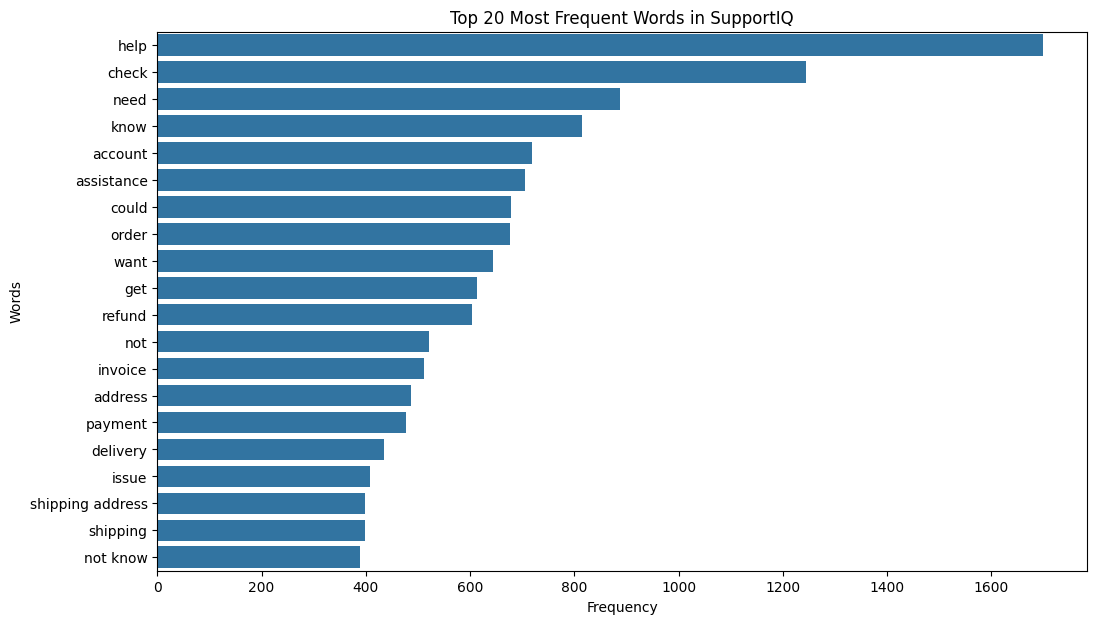

In [38]:
word_frequency = np.asarray(
    x_train_bow.sum(axis=0)
).flatten()

word_frequency_df = pd.DataFrame({
    "word": vocabulary,
    "frequency": word_frequency
})

top_words = word_frequency_df.sort_values(
    by="frequency",
    ascending=False
).head(20)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_words,
    x="frequency",
    y="word"
)

plt.title("Top 20 Most Frequent Words in SupportIQ")
plt.xlabel("Frequency")
plt.ylabel("Words")

plt.show()

In [39]:
import joblib
from scipy.sparse import save_npz

# Save vectorizer
joblib.dump(
    bow_vectorizer,
    "/content/sample_data/bow_vectorizer.pkl"
)

['/content/sample_data/bow_vectorizer.pkl']